# Task 3 — Midterm Project
**Student:** Олжабай Ибрахим · **SEED = 2586** 

In [1]:
import sys, warnings, numpy as np, pandas as pd, sklearn, joblib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
print(sys.version.split()[0], np.__version__, pd.__version__, sklearn.__version__)
SEED = 2586

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print(train.shape, test.shape)

3.12.9 2.3.4 2.3.3 1.7.2
(32940, 22) (8236, 20)


## Stage 1 — Framing
We predict if a client says "yes" to a term deposit. The bank can call only 10 % of clients, so we need a good ranking of clients. I use ROC-AUC and average precision. Accuracy is not useful.

`test.csv` has no `y` and no `duration`. The call duration is known only after the call, so it cannot be used as a feature. I also drop `id`.

In [2]:
print("only in train:", set(train.columns) - set(test.columns))
y = (train["y"] == "yes").astype(int)
X = train.drop(columns=["id", "y", "duration"])
print(X.shape, y.shape)

only in train: {'y', 'duration'}
(32940, 19) (32940,)


## Stage 2 — Data
- Only 11.3 % of clients say "yes". A model that always says "no" has accuracy **0.887**, but finds nobody (ROC-AUC 0.5).
- No `NaN`, but "unknown" means missing: default 6 871, education 1 401, housing 794, loan 794, job 275, marital 64.
- `pdays = 999` means "not contacted before": 31 694 rows (96.2 %). It is a sentinel, not a real number of days.
- The rows are in random order (months are mixed), so the order has no time meaning.
- Share of "yes": 64.8 % after a previous success vs 8.8 % with no previous campaign; 14.7 % for cellular vs 5.3 % for telephone.
- Correlation with the target: nr.employed −0.356, pdays −0.328, euribor3m −0.308, previous +0.232.

In [3]:
print("share of yes:", round(y.mean(), 3), "| accuracy of always no:", round(1 - y.mean(), 3))
unk = (train == "unknown").sum()
print(unk[unk > 0])
print("pdays == 999:", (train["pdays"] == 999).sum(), round((train["pdays"] == 999).mean(), 3))
print(train["month"].head(10).tolist())

t = train.assign(target=y)
print(t.groupby("poutcome")["target"].mean().round(3))
print(t.groupby("contact")["target"].mean().round(3))

share of yes: 0.113 | accuracy of always no: 0.887
job           275
marital        64
education    1401
default      6871
housing       794
loan          794
dtype: int64
pdays == 999: 31694 0.962
['may', 'aug', 'aug', 'may', 'jun', 'aug', 'may', 'apr', 'jul', 'nov']
poutcome
failure        0.140
nonexistent    0.088
success        0.648
Name: target, dtype: float64
contact
cellular     0.147
telephone    0.053
Name: target, dtype: float64


nr.employed      -0.356
pdays            -0.328
euribor3m        -0.308
emp.var.rate     -0.299
cons.price.idx   -0.134
campaign         -0.065
age               0.032
cons.conf.idx     0.058
previous          0.232
Name: target, dtype: float64


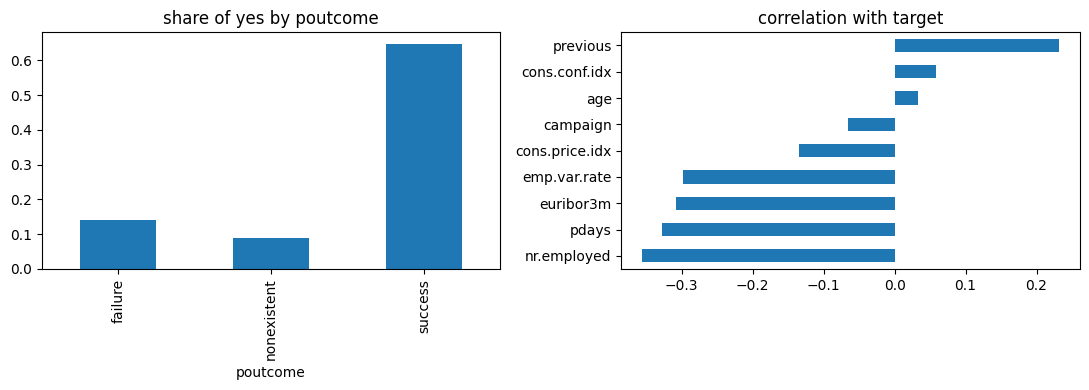

In [4]:
num = ["age", "campaign", "previous", "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
corr = t[num + ["pdays", "target"]].corr()["target"].drop("target").sort_values()
print(corr.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
t.groupby("poutcome")["target"].mean().plot.bar(ax=ax[0], title="share of yes by poutcome")
corr.plot.barh(ax=ax[1], title="correlation with target")
plt.tight_layout()
plt.show()

## Stage 3 — Validation
I keep 20 % of `train.csv` as my own hold-out and do not touch it until Stage 7. Everything else uses 5-fold stratified cross-validation on the rest. I use stratified folds because only 11 % of rows are "yes", and stratification keeps this share in every fold. I report mean ± std over the folds. If two models differ by less than the std, I do not call one of them better.

In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

X_dev, X_hold, y_dev, y_hold = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X_dev.shape, X_hold.shape)

(26352, 19) (6588, 19)


## Stage 4 — Preprocessing in a pipeline
All steps (scaling, encoding, imputing) are inside one `Pipeline`, so in cross-validation they learn only from the training folds. The check below shows it: the scaler mean of `age` equals the mean of the training fold (40.051), not the mean of all data (40.049).

Choices: numbers are standardised, categories are one-hot encoded, and for `pdays` the value 999 is replaced by the median of the real values plus a 0/1 flag "contacted before".

I compared "unknown" as its own category with "unknown" replaced by the most frequent value. ROC-AUC is 0.7852 ± 0.0092 and 0.7854 ± 0.0095. The difference is far smaller than the std, so it does not matter. I keep "unknown" as its own category because it is simpler and may carry information.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

cat = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]

def make_pre(unknown_missing=False):
    pdays_part = Pipeline([("imp", SimpleImputer(missing_values=999, strategy="median", add_indicator=True)),
                           ("scale", StandardScaler())])
    if unknown_missing:
        cat_part = Pipeline([("imp", SimpleImputer(missing_values="unknown", strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    else:
        cat_part = OneHotEncoder(handle_unknown="ignore")
    return ColumnTransformer([("num", StandardScaler(), num),
                              ("pdays", pdays_part, ["pdays"]),
                              ("cat", cat_part, cat)])

In [7]:
fold_train, fold_val = next(cv.split(X_dev, y_dev))
model = Pipeline([("pre", make_pre()), ("clf", LogisticRegression(max_iter=2000))])
model.fit(X_dev.iloc[fold_train], y_dev.iloc[fold_train])
scaler = model.named_steps["pre"].named_transformers_["num"]
print("scaler mean of age:     ", round(scaler.mean_[0], 3))
print("mean age, training fold:", round(X_dev.iloc[fold_train]["age"].mean(), 3))
print("mean age, all dev data: ", round(X_dev["age"].mean(), 3))

scaler mean of age:      40.051
mean age, training fold: 40.051
mean age, all dev data:  40.049


In [8]:
def cv_scores(model):
    s = cross_validate(model, X_dev, y_dev, cv=cv, scoring=["roc_auc", "average_precision"])
    auc, ap = s["test_roc_auc"], s["test_average_precision"]
    return f"ROC-AUC {auc.mean():.4f} ± {auc.std():.4f} | AP {ap.mean():.4f} ± {ap.std():.4f}"

for um in (False, True):
    model = Pipeline([("pre", make_pre(um)), ("clf", LogisticRegression(max_iter=2000))])
    print("unknown as missing:", um, "->", cv_scores(model))

unknown as missing: False -> ROC-AUC 0.7852 ± 0.0092 | AP 0.4435 ± 0.0170
unknown as missing: True -> ROC-AUC 0.7854 ± 0.0095 | AP 0.4434 ± 0.0171


## Stage 5 — Baselines
On the same folds, the majority-class model has accuracy 0.887 but ROC-AUC 0.5000 ± 0.0000 and average precision 0.113. So accuracy is misleading on these data. Logistic regression has ROC-AUC 0.7852 ± 0.0092 and average precision 0.4435 ± 0.0170. These numbers are the bar for all later models.

In [9]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="prior")
acc = cross_validate(dummy, X_dev, y_dev, cv=cv, scoring="accuracy")["test_score"]
print("majority accuracy:", round(acc.mean(), 4), "±", round(acc.std(), 4))
print("majority class:     ", cv_scores(dummy))

simple = Pipeline([("pre", make_pre()), ("clf", LogisticRegression(max_iter=2000))])
print("logistic regression:", cv_scores(simple))

majority accuracy: 0.8873 ± 0.0001
majority class:      ROC-AUC 0.5000 ± 0.0000 | AP 0.1127 ± 0.0001
logistic regression: ROC-AUC 0.7852 ± 0.0092 | AP 0.4435 ± 0.0170


## Stage 6 — Models and tuning
Three model families, same pipeline, same folds. I tried these values (cross-validation on the training part only, metric ROC-AUC): logistic regression C in {0.01, 0.1, 1, 10}; decision tree max_depth in {3, 5, 8} with min_samples_leaf = 10; random forest (150 trees) max_depth in {6, 10} with min_samples_leaf = 10.

| model | best value | ROC-AUC | average precision |
|---|---|---|---|
| logistic regression | C = 0.1 | 0.7854 ± 0.0099 | 0.4424 ± 0.0186 |
| decision tree | max_depth = 8 | 0.7754 ± 0.0073 | 0.4048 ± 0.0115 |
| random forest | max_depth = 10 | 0.7928 ± 0.0083 | 0.4577 ± 0.0145 |

**Imbalance.** With `class_weight="balanced"` the ROC-AUC of logistic regression changes from 0.7854 to 0.7860 (+0.0006). This is much smaller than the fold std (about 0.01), so handling the imbalance does not help.

**Choice.** Forest vs logistic regression differ by 0.0074, less than one std, so there is no clear winner. The tree is about two std below the forest, so it is the weakest. All three are far above the baseline. I choose the simpler **logistic regression (C = 0.1)**.

In [10]:
for C in [0.01, 0.1, 1, 10]:
    model = Pipeline([("pre", make_pre()), ("clf", LogisticRegression(C=C, max_iter=2000))])
    print("logreg C =", C, "->", cv_scores(model))

logreg C = 0.01 -> ROC-AUC 0.7835 ± 0.0098 | AP 0.4386 ± 0.0200
logreg C = 0.1 -> ROC-AUC 0.7854 ± 0.0099 | AP 0.4424 ± 0.0186
logreg C = 1 -> ROC-AUC 0.7852 ± 0.0092 | AP 0.4435 ± 0.0170
logreg C = 10 -> ROC-AUC 0.7851 ± 0.0091 | AP 0.4437 ± 0.0162


In [11]:
from sklearn.tree import DecisionTreeClassifier

for d in [3, 5, 8]:
    model = Pipeline([("pre", make_pre()),
                      ("clf", DecisionTreeClassifier(max_depth=d, min_samples_leaf=10, random_state=SEED))])
    print("tree max_depth =", d, "->", cv_scores(model))

tree max_depth = 3 -> ROC-AUC 0.7419 ± 0.0096 | AP 0.3633 ± 0.0056
tree max_depth = 5 -> ROC-AUC 0.7653 ± 0.0099 | AP 0.3987 ± 0.0097
tree max_depth = 8 -> ROC-AUC 0.7754 ± 0.0073 | AP 0.4048 ± 0.0115


In [12]:
from sklearn.ensemble import RandomForestClassifier

for d in [6, 10]:
    model = Pipeline([("pre", make_pre()),
                      ("clf", RandomForestClassifier(n_estimators=150, max_depth=d, min_samples_leaf=10,
                                                     random_state=SEED, n_jobs=-1))])
    print("forest max_depth =", d, "->", cv_scores(model))

forest max_depth = 6 -> ROC-AUC 0.7891 ± 0.0083 | AP 0.4483 ± 0.0175
forest max_depth = 10 -> ROC-AUC 0.7928 ± 0.0083 | AP 0.4577 ± 0.0145


In [13]:
for w in [None, "balanced"]:
    model = Pipeline([("pre", make_pre()),
                      ("clf", LogisticRegression(C=0.1, class_weight=w, max_iter=2000))])
    print("logreg, class_weight =", w, "->", cv_scores(model))

logreg, class_weight = None -> ROC-AUC 0.7854 ± 0.0099 | AP 0.4424 ± 0.0186
logreg, class_weight = balanced -> ROC-AUC 0.7860 ± 0.0092 | AP 0.4386 ± 0.0187


## Stage 7 — Final evaluation (hold-out, once)
The chosen model (logistic regression, C = 0.1) was fitted on the training part and scored once on my hold-out (6 588 clients): **ROC-AUC 0.8167, average precision 0.4927** (curves below). This is higher than the cross-validation value (0.785 ± 0.010), so the hold-out is a bit lucky and I trust the cross-validation more.

**10 % rule.** The cutoff is the 90th percentile of the scores (0.288), so 659 clients are called. Precision is **0.511**, recall **0.454**, lift **4.54** over calling at random (base rate 0.113).

**For the manager.** Of the 659 clients we call, about 337 say yes and 322 do not. About 405 clients who would say yes are not called, because we can call only 10 %. We reach about 45 % of all buyers with 10 % of the calls, and half of our calls succeed, against about 11 % at random.

**Random split.** In real use we train on the past and call in the future. A random split puts clients from the same weeks in both parts, and they share the same macro values (euribor3m, employment). The future will have new conditions, so real results will probably be lower.

In [14]:
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, confusion_matrix

final = Pipeline([("pre", make_pre()), ("clf", LogisticRegression(C=0.1, max_iter=2000))])
final.fit(X_dev, y_dev)
score = final.predict_proba(X_hold)[:, 1]

auc = roc_auc_score(y_hold, score)
ap = average_precision_score(y_hold, score)
print("hold-out ROC-AUC:", round(auc, 4), "| average precision:", round(ap, 4))

hold-out ROC-AUC: 0.8167 | average precision: 0.4927


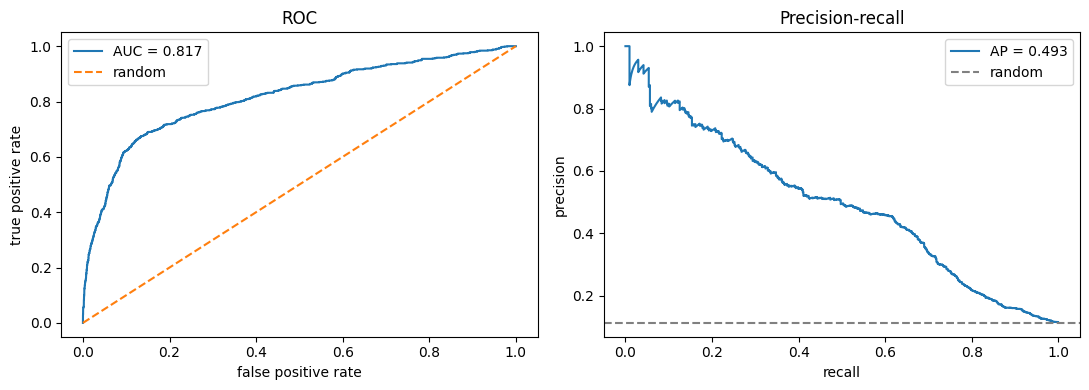

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

fpr, tpr, _ = roc_curve(y_hold, score)
ax[0].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
ax[0].plot([0, 1], [0, 1], "--", label="random")
ax[0].set_xlabel("false positive rate")
ax[0].set_ylabel("true positive rate")
ax[0].set_title("ROC")
ax[0].legend()

prec, rec, _ = precision_recall_curve(y_hold, score)
ax[1].plot(rec, prec, label=f"AP = {ap:.3f}")
ax[1].axhline(y_hold.mean(), ls="--", c="gray", label="random")
ax[1].set_xlabel("recall")
ax[1].set_ylabel("precision")
ax[1].set_title("Precision-recall")
ax[1].legend()

plt.tight_layout()
plt.show()

In [16]:
cut = np.quantile(score, 0.90)
pred = (score >= cut).astype(int)

tn, fp, fn, tp = confusion_matrix(y_hold, pred).ravel()
precision = tp / (tp + fp)
recall = tp / (tp + fn)
print("called:", pred.sum(), "| cutoff:", round(cut, 4))
print("TN, FP, FN, TP:", tn, fp, fn, tp)
print("precision:", round(precision, 3), "| recall:", round(recall, 3),
      "| lift:", round(precision / y_hold.mean(), 2))

called: 659 | cutoff: 0.2878
TN, FP, FN, TP: 5524 322 405 337
precision: 0.511 | recall: 0.454 | lift: 4.54


## Stage 8 — Saving the model
The same pipeline is refitted on all of `train.csv` and saved as `model.joblib`. It accepts the raw columns of `test.csv` without `id`, with no manual step. `predictions.csv` has `id`, `y_pred` (1 for the top 10 % of scores, 824 of 8 236 clients) and `y_score`. I checked in a new terminal that `model.joblib` loads in a fresh Python process and scores rows of `test.csv`.

In [17]:
final_all = Pipeline([("pre", make_pre()), ("clf", LogisticRegression(C=0.1, max_iter=2000))])
final_all.fit(X, y)
joblib.dump(final_all, "model.joblib")

['model.joblib']

In [18]:
test_scores = final_all.predict_proba(test.drop(columns=["id"]))[:, 1]
test_cut = np.quantile(test_scores, 0.90)

out = pd.DataFrame({"id": test["id"],
                    "y_pred": (test_scores >= test_cut).astype(int),
                    "y_score": test_scores})
out.to_csv("predictions.csv", index=False)
print(out.shape, out["y_pred"].sum())

(8236, 3) 824
